# Running and evaluating an ensemble weather forecast

Running Aurora Ensemble 1.5 with ERA5: 
- inspect the initial conditions
- run Aurora 1.5 ENS as a 10-member ensemble over 7 days
- compare against ERA5 analysis.


## Import packages

In [2]:
import sys, subprocess
sys.path.insert(0, "..")

import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display

from weather_pipeline.datasource import build_data_source
from weather_pipeline.postprocess import load_forecast
from weather_pipeline.scoring import (
    compute_difference, compute_metrics, ensemble_dim, fetch_truth,
)
from weather_pipeline.plotting import render_rotating_gif, ensemble_gif


## Set config

In [3]:
plt.rcParams["figure.dpi"] = 110

CENTER_LON = 0
MODEL      = "aurora1.5-ens"
INIT_TIME  = "2026-03-13T00:00:00"
N_MEMBERS  = 10
LEAD_DAYS  = 2

# Aurora 1.5's Earth2Studio wrapper steps HOURLY, so 7 days = 168 steps.
STEP_HOURS = 1
N_STEPS    = LEAD_DAYS * 24 // STEP_HOURS

OUT = f"../weather-benchmark/outputs/forecasts/{MODEL}_{pd.Timestamp(INIT_TIME).strftime('%Y%m%dT%H%M')}.zarr"
print(f"{LEAD_DAYS} days = {N_STEPS} steps of {STEP_HOURS} h")

2 days = 48 steps of 1 h


## Load the initial conditions from ERA5

In [4]:
source = build_data_source("era5")

t = pd.Timestamp(INIT_TIME)
era5_times = source.single.time.values
print(f"ERA5 archive: {era5_times[0]} .. {era5_times[-1]}")
assert era5_times[0] <= np.datetime64(t) <= era5_times[-1], \
    f"{INIT_TIME} is outside the ERA5 archive (it lags real time by ~a quarter)"

# Temperature and both wind components at the init time.
ic = source([t], ["t2m", "u10m", "v10m"])
ic = ic.isel(time=0).rename({"lat": "latitude", "lon": "longitude"})

t2m_c = ic.sel(variable="t2m", drop=True) - 273.15
u10  = ic.sel(variable="u10m", drop=True)
v10  = ic.sel(variable="v10m", drop=True)

# Wind SPEED is computed from the components: sqrt(u^2+v^2) 
wind = np.sqrt(u10**2 + v10**2)
wind.name = "wind10m"

print(f"t2m  {float(t2m_c.min()):.1f} .. {float(t2m_c.max()):.1f} °C")
print(f"wind {float(wind.min()):.1f} .. {float(wind.max()):.1f} m/s")

ERA5 archive: 1940-01-01T00:00:00.000000000 .. 2026-03-31T23:00:00.000000000
t2m  -53.4 .. 38.4 °C
wind 0.0 .. 25.0 m/s


## Plot initial conditions

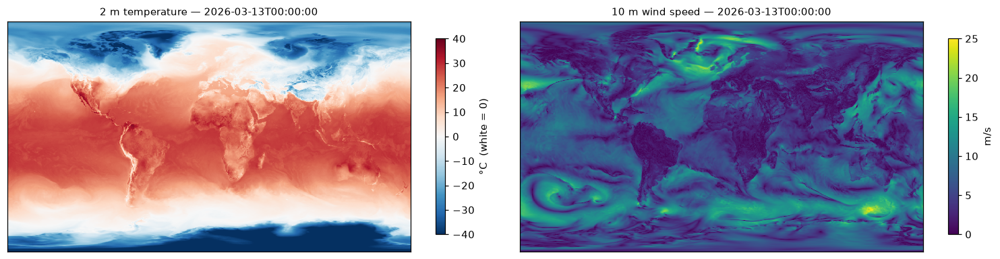

In [5]:
def recenter(da, center_lon=CENTER_LON):
    lon = ((da["longitude"].values - center_lon + 180) % 360) - 180
    return da.assign_coords(longitude=lon).sortby("longitude")

t2m_plot, wind_plot = recenter(t2m_c), recenter(wind)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))

im = axes[0].pcolormesh(t2m_plot.longitude, t2m_plot.latitude, t2m_plot.values,
                        cmap="RdBu_r", vmin=-40, vmax=40, shading="auto")
axes[0].set_title(f"2 m temperature — {INIT_TIME}", fontsize=10)
fig.colorbar(im, ax=axes[0], shrink=0.85, label="°C  (white = 0)")

im = axes[1].pcolormesh(wind_plot.longitude, wind_plot.latitude, wind_plot.values,
                        cmap="viridis", vmin=0, vmax=25, shading="auto")
axes[1].set_title(f"10 m wind speed — {INIT_TIME}", fontsize=10)
fig.colorbar(im, ax=axes[1], shrink=0.85, label="m/s")

for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

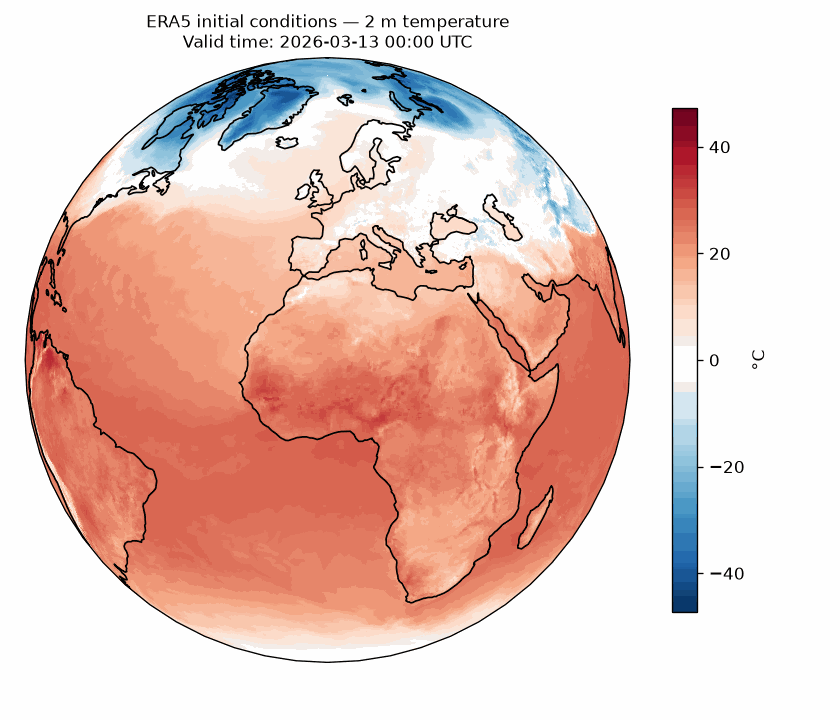

'../weather-benchmark/outputs/tutorial_ic_t2m.gif'

In [14]:
def as_series(da):
    return da.expand_dims(valid_time=[np.datetime64(t)])

render_rotating_gif(
    as_series(t2m_c), "../weather-benchmark/outputs/tutorial_ic_t2m.gif",
    title="ERA5 initial conditions — 2 m temperature",
    unit_label="°C", cmap="RdBu_r", center=0,
    frames_per_step=36, display=True,
)

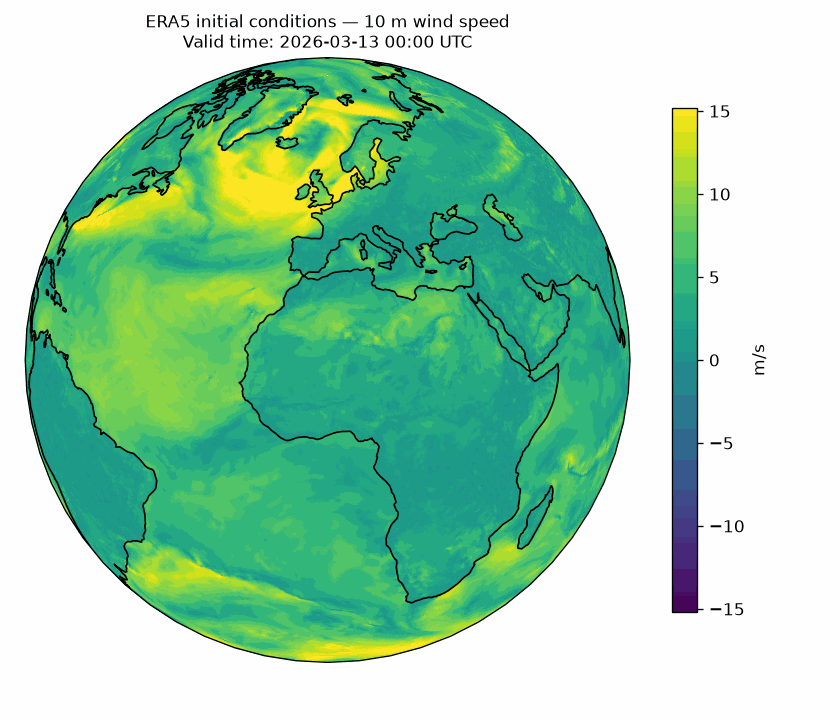

'../weather-benchmark/outputs/tutorial_ic_wind.gif'

In [15]:
def as_series(da):
    return da.expand_dims(valid_time=[np.datetime64(t)])

render_rotating_gif(
    as_series(wind), "../weather-benchmark/outputs/tutorial_ic_wind.gif",
    title="ERA5 initial conditions — 10 m wind speed",
    unit_label="m/s", cmap="viridis", center=0,
    frames_per_step=36, display=True,
)

## Run ensemble model 

In [ ]:
N_STEPS_RUN, N_MEMBERS_RUN = N_STEPS, N_MEMBERS

cmd = [
    "uv", "run", "scripts/run_benchmark.py",
    "--models", MODEL,
    "--n-members", str(N_MEMBERS_RUN),
    "--source", "era5",
    "--init-times", INIT_TIME,
    "--n-steps", str(N_STEPS_RUN),
    "--variable", "t2m",
]
print(" ".join(cmd))
subprocess.run(cmd, cwd="..", check=True)

## Load forecast

In [6]:
fc_all = load_forecast(OUT, ["t2m", "u10m", "v10m"])
ENS = ensemble_dim(fc_all["t2m"])
print(f"{fc_all.sizes[ENS]} members, {fc_all.sizes['valid_time']} lead times")

# Subsample to 6-hourly: hourly output is a lot of frames, and 6 h is the
# cadence the AIFS models use, so results stay comparable. Drop h=0, which
# is the analysis rather than a forecast.
hours = (fc_all["lead_time"].values / np.timedelta64(1, "h")).astype(int)
keep = (hours > 0) & (hours % 6 == 0)
fc = fc_all.isel(valid_time=np.flatnonzero(keep))
lead_h = (fc["lead_time"].values / np.timedelta64(1, "h")).astype(int)

fc_t2m  = fc["t2m"]
fc_wind = np.sqrt(fc["u10m"]**2 + fc["v10m"]**2)
fc_wind.name = "wind10m"
print(f"scoring {len(lead_h)} lead times: {lead_h[0]} .. {lead_h[-1]} h")

/fsx/emma_scharfmann/weather-benchmark/weather_pipeline/postprocess.py:23: UserWarning: Following pandas, xarray only supports decoding to timedelta64 values with a resolution of 's', 'ms', 'us', or 'ns'. Encoded values for variable 'lead_time' have a resolution of 'h'. Attempting to decode to a resolution of 's'. Note, depending on the encoded values, this may lead to an OverflowError. Additionally, data will not be identically round tripped; xarray will choose an encoding dtype of 'timedelta64[s]' when re-encoding.
  ds = xr.open_zarr(zarr_path)


10 members, 49 lead times
scoring 8 lead times: 6 .. 48 h


## Plot forecast

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


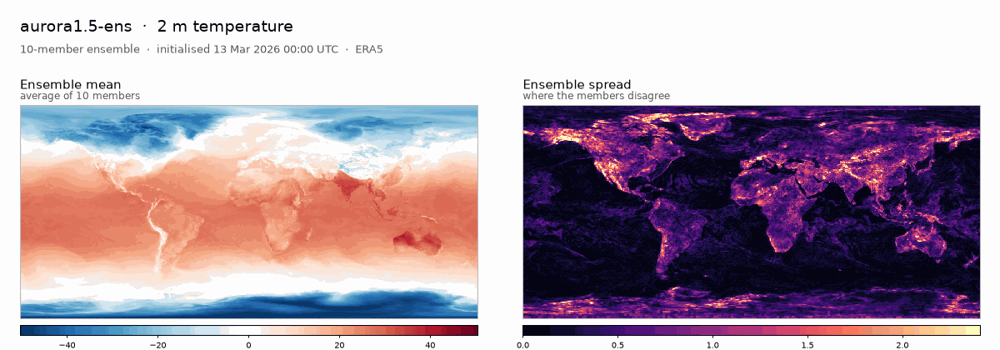

In [5]:
ensemble_gif(fc_t2m - 273.15, "2 m temperature [°C]", "RdBu_r", ENS, MODEL, INIT_TIME, 
             f"{MODEL}_t2m_ensemble.gif", center=0)

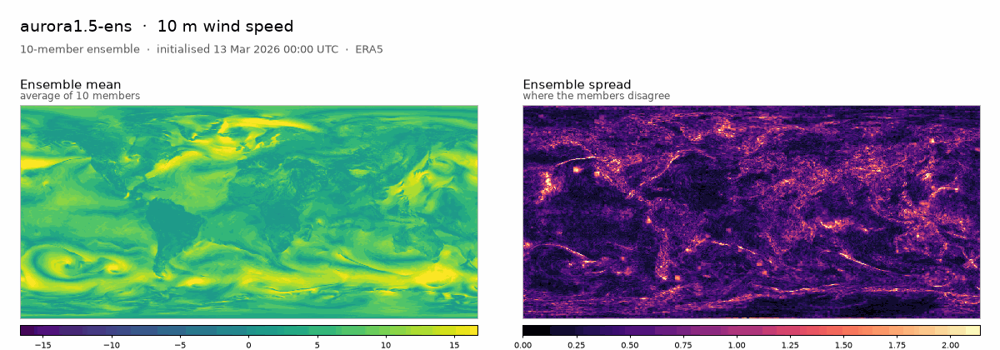

In [6]:
ensemble_gif(fc_wind , "10 m wind speed [m/s]", "viridis", ENS, MODEL, INIT_TIME, 
             f"{MODEL}_t2m_ensemble.gif", center=0)

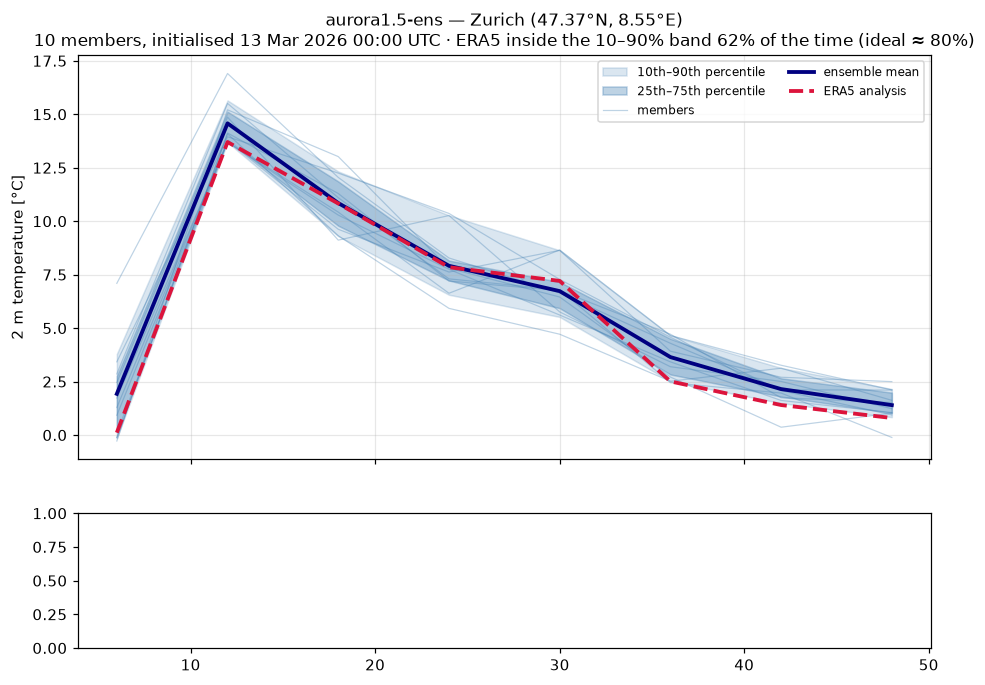

In [16]:
SITE_NAME = "Zurich"
SITE_LAT, SITE_LON = 47.37, 8.55        # lon in 0-360, as stored

truth_t2m = fetch_truth(source, "t2m", fc["valid_time"].values)["t2m"]

def at_point(da, lat, lon):
    return da.sel(latitude=lat, longitude=lon % 360, method="nearest")

fc_pt    = at_point(fc_t2m, SITE_LAT, SITE_LON) - 273.15
truth_pt = at_point(truth_t2m, SITE_LAT, SITE_LON) - 273.15

mean = fc_pt.mean(dim=ENS).values
p10  = fc_pt.quantile(0.10, dim=ENS).values
p25  = fc_pt.quantile(0.25, dim=ENS).values
p75  = fc_pt.quantile(0.75, dim=ENS).values
p90  = fc_pt.quantile(0.90, dim=ENS).values
obs  = truth_pt.values

fig, (ax, axe) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})

# Nested percentile bands: the darker inner band is the central half of the
# members, the lighter outer one the 10th-90th. Reading them together shows
# not just how wide the ensemble is but how its mass is distributed.
ax.fill_between(lead_h, p10, p90, color="steelblue", alpha=0.20,
                label="10th–90th percentile")
ax.fill_between(lead_h, p25, p75, color="steelblue", alpha=0.35,
                label="25th–75th percentile")
for m in range(fc_pt.sizes[ENS]):
    ax.plot(lead_h, fc_pt.isel({ENS: m}).values, color="steelblue",
            alpha=0.35, lw=0.8)
ax.plot([], [], color="steelblue", alpha=0.35, lw=0.8, label="members")
ax.plot(lead_h, mean, color="navy", lw=2.5, label="ensemble mean")
ax.plot(lead_h, obs, color="crimson", lw=2.5, ls="--", label="ERA5 analysis")

inside = ((obs >= p10) & (obs <= p90)).mean()
ax.set_ylabel("2 m temperature [°C]")
ax.set_title(
    f"{MODEL} — {SITE_NAME} ({SITE_LAT:.2f}°N, {SITE_LON:.2f}°E)\n"
    f"{fc_pt.sizes[ENS]} members, initialised "
    f"{pd.Timestamp(INIT_TIME).strftime('%d %b %Y %H:%M UTC')} · "
    f"ERA5 inside the 10–90% band {100*inside:.0f}% of the time (ideal ≈ 80%)",
    fontsize=11,
)
ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2, loc="best")


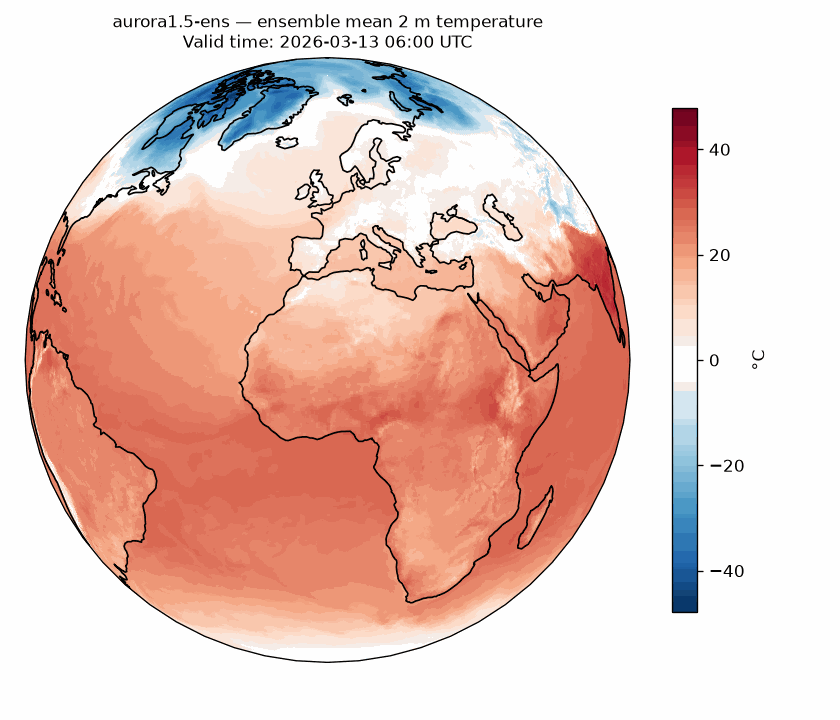

'../weather-benchmark/outputs/aurora1.5-ens_t2m_rotating.gif'

In [8]:
mean_c = fc_t2m.mean(dim=ENS) - 273.15
mean_c.name = "t2m_mean"

render_rotating_gif(
    mean_c,
    f"../weather-benchmark/outputs/{MODEL}_t2m_rotating.gif",
    title=f"{MODEL} — mean ensemble 10 m wind speed [m/s]",
    unit_label="°C",
    cmap="RdBu_r",
    center=0,                 # white = 0 °C
    frames_per_step=6,
    n_turns=1,
    display=True,
)

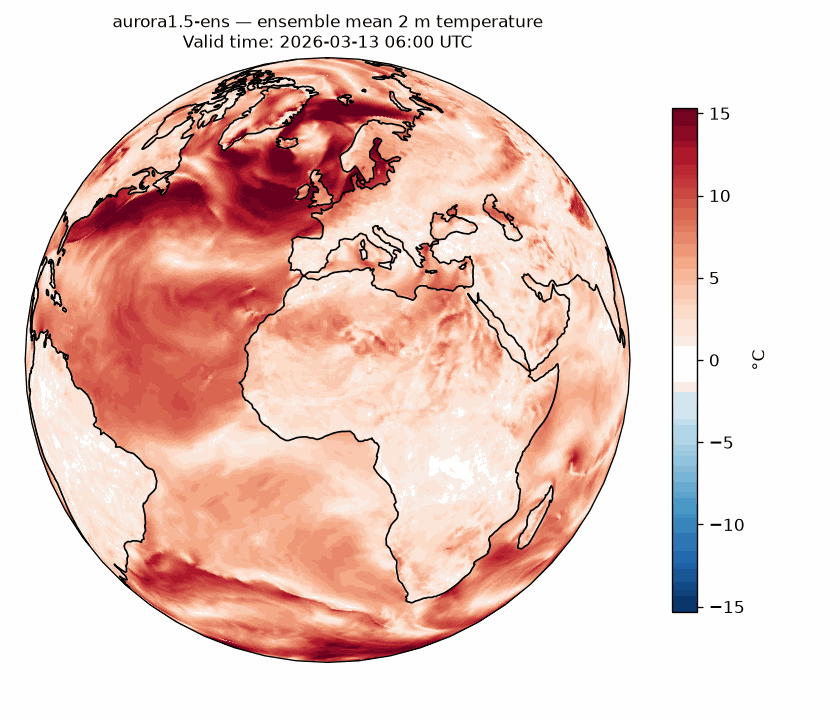

'../weather-benchmark/outputs/aurora1.5-ens_t2m_rotating.gif'

In [9]:
mean_c = fc_wind.mean(dim=ENS)
mean_c.name = "wind_mean"

render_rotating_gif(
    mean_c,
    f"../weather-benchmark/outputs/{MODEL}_t2m_rotating.gif",
    title=f"{MODEL} — ensemble mean 2 m temperature",
    unit_label="°C",
    cmap="RdBu_r",
    center=0,                 # white = 0 °C
    frames_per_step=6,
    n_turns=1,
    display=True,
)

In [10]:
import matplotlib as mpl

# Wind speed is strongly right-skewed: most of the globe is under 10 m/s
# and cyclones sit in the top few percent. A linear scale therefore spends
# its whole range on the calm background. PowerNorm with gamma > 1 pushes
# colour resolution toward the high end, so storms separate from the
# merely-breezy instead of both reading as "yellow".
norm = mpl.colors.PowerNorm(gamma=2.0, vmin=0, vmax=30)

In [11]:
CMAP = "magma"     # or "inferno" / "turbo"

In [ ]:
render_rotating_gif(
    fc_wind.mean(dim=ENS),
    f"../weather-benchmark/outputs/{MODEL}_t2m_rotating.gif",
    title=f"{MODEL} — ensemble mean 2 m temperature",
    unit_label="m/s",
    cmap="RdBu_r",
    frames_per_step=6,
    n_turns=1,
    display=True,
)